# 01 — Method validation

**Purpose.** Show that the building blocks are correct *before* any comparison is made:

1. the simulator and the 1D CRR reference behave as theory says;
2. LSM and the neural stopping policy both recover the 1D Bermudan put value;
3. tuned LSM converges to the published 2D/5D max-call references as training paths grow;
4. **implementation check:** the neural method trained in the *paper's own regime* (fresh paths every step, raw inputs + payoff, width d+40, batch norm) reaches the published 5D value.

Settings here are fixed in `CONFIG` in advance and are **not** tuned towards the reference values.
Nothing in this notebook feeds into the main study's choices except as a sanity check.

Run order: **01 → 02 → 03**. Set `MODE` in the first cell. Full mode takes roughly 15 minutes (most of it is the paper-regime check).

In [1]:
MODE = "quick"   # "quick" = smoke test (minutes, numbers are NOT results) | "full" = research run

import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stopping import *          # all methods live in stopping.py (one file, read top to bottom)

print("Thread limits:", limit_threads(1))   # NumPy/BLAS AND PyTorch single-threaded: fair CPU timing
BASE = CONFIG[MODE]["base_seed"]
OUT = results_dir(MODE)                     # results/quick or results/full
print("Mode:", MODE, "| results ->", OUT)
cfg = CONFIG[MODE]["validation"]
CHECK_SEED = 500   # seeds/paths used here are disjoint from the main study (seeds 0-9) and calibration (100+)
cfg

Thread limits: {'torch_threads': 1, 'blas': ['openmp:1', 'openblas:1', 'openblas:1']}
Mode: quick | results -> results/quick


{'put_train': 2000,
 'put_seeds': 1,
 'val': 1000,
 'test': 20000,
 'lsm_budgets': [500, 2000, 10000],
 'nn_settings': {'max_steps': 150, 'lr': 0.001, 'batch': 256},
 'paper_check': {'max_steps': 60, 'batch': 1024}}

## 1. Simulator and reference checks
Exact GBM transitions, risk-neutral drift, correlation, nested training sets within a seed, and CRR tree convergence.

In [2]:
put = validation_put()
x = gbm_paths(put, 50_000, seed=1)
expected = put.s0 * np.exp((put.rate - put.dividend) * put.maturity)
assert abs(x[:, -1, 0].mean() - expected) < 4 * x[:, -1, 0].std() / np.sqrt(len(x)), "risk-neutral mean"

corr_opt = Option(kind="max_call", d=3, rho=0.3, dividend=0.1, maturity=3.0)
r = np.diff(np.log(gbm_paths(corr_opt, 50_000, seed=2)), axis=1)[:, 0, :]
assert abs(np.corrcoef(r.T)[0, 1] - 0.3) < 0.02, "correlation"

opt5 = paper_max_call(5)
assert np.array_equal(gbm_paths(opt5, 1_000, seed=3), gbm_paths(opt5, 5_000, seed=3)[:1_000]), "nested training sets"

# Discounting and exercise mechanics of the forward evaluator
paths = gbm_paths(put, 1_000, seed=4)
never = Policy("never")                                         # no rules: hold to maturity
v, tau = discounted_payoffs(put, paths, never)
assert np.allclose(v, put.payoff(paths[:, -1, :]) * np.exp(-put.rate * put.maturity)) and (tau == put.dates).all(), "terminal discounting"
first = Policy("first", rules={1: lambda z: np.ones(len(z), bool)})   # exercise at t_1 whenever in the money
v, tau = discounted_payoffs(put, paths, first)
g1 = put.payoff(paths[:, 1, :])
assert np.allclose(v[g1 > 0], g1[g1 > 0] * np.exp(-put.rate * put.dt)) and (tau[g1 > 0] == 1).all(), "early-exercise discounting"
assert (tau[g1 == 0] > 1).all(), "never exercise out of the money"
print("Discounting and exercise checks passed.")

crr = {n: crr_bermudan_put(put, n) for n in (40, 80, 160, 320)}
assert all(abs(crr[n] - crr[320]) < 0.01 for n in (80, 160)), "CRR convergence"
assert crr[320] >= 5.5735 - 1e-3, "Bermudan put >= European put (5.5735)"
print("CRR Bermudan put by steps per exercise interval:", {k: round(v, 5) for k, v in crr.items()})
put_ref = reference_for(put)
print("1D reference:", put_ref)
print("Published max-call references:", {d: PAPER_REFERENCES[d]["value"] for d in PAPER_REFERENCES})

Discounting and exercise checks passed.
CRR Bermudan put by steps per exercise interval: {40: 6.02575, 80: 6.02648, 160: 6.02719, 320: 6.02738}
1D reference: {'value': 6.027383085500176, 'low': 6.027185253706979, 'high': 6.027580917293373, 'source': 'CRR tree, 320 steps per exercise interval (band = refinement difference)'}
Published max-call references: {2: 13.902, 5: 26.159, 10: 38.337}


## 2. 1D Bermudan put: LSM and neural policy against CRR
In 1D sorting is the identity, so the neural input is (log price, payoff). Values are on independent test paths;
the interval is the Monte Carlo interval of the test sample (conditional on the fitted policy).

In [3]:
test_put = gbm_paths(put, cfg["test"], seed_for(BASE, "test", 1))
put_rows = []
for seed in range(CHECK_SEED, CHECK_SEED + cfg["put_seeds"]):
    unit = run_unit(put, cfg["put_train"], seed, ["sorted+payoff"], NeuralSettings(**cfg["nn_settings"]),
                    cfg["val"], test_put, put_ref, BASE)
    put_rows += unit["runs"]
put_df = pd.DataFrame(put_rows)
put_df["ci95"] = 1.96 * put_df.test_se
put_df.to_csv(OUT / "validation_put.csv", index=False)
print(f"CRR reference: {put_ref['value']:.4f}")
put_df[["seed", "method", "guarded", "value", "ci95", "gap", "n_guarded_dates", "train_s"]].round(4)

CRR reference: 6.0274


,seed,method,guarded,value,ci95,gap,n_guarded_dates,train_s
0,500,lsm,True,6.0981,0.1049,-0.0708,2,0.0034
1,500,lsm,False,6.1086,0.1011,-0.0812,2,0.0034
2,500,nn_sorted+payoff,True,6.0976,0.1027,-0.0702,2,2.3260
3,500,nn_sorted+payoff,False,6.0847,0.0974,-0.0573,2,2.3260


## 3. LSM convergence on the paper's max-calls
Tuned LSM (degree and ridge chosen on validation paths) for increasing training budgets, one seed.
The shaded band is the *published reference's own* uncertainty; gaps inside it are not interpretable.

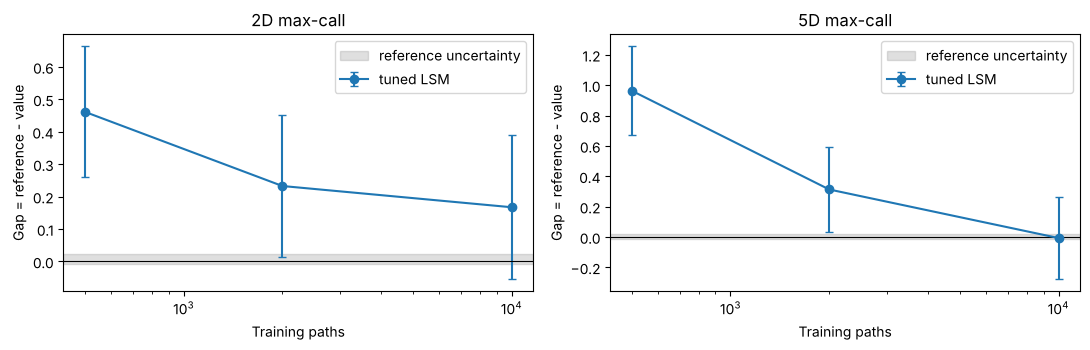

,d,budget,value,ci95,gap,degree,ridge,selection_s
0,2,500,13.4406,0.2026,0.4614,2,0.0000,0.1060
1,2,2000,13.6694,0.2185,0.2326,3,0.0100,0.1731
2,2,10000,13.7349,0.2227,0.1671,2,0.0100,0.4651
3,5,500,25.1955,0.2933,0.9635,1,0.0001,0.2698
4,5,2000,25.8462,0.2812,0.3128,3,0.0100,0.6872
5,5,10000,26.1661,0.2725,-0.0071,3,0.0100,2.2550


In [4]:
lsm_rows = []
for d in (2, 5):
    opt = paper_max_call(d)
    ref = reference_for(opt)
    test = gbm_paths(opt, cfg["test"], seed_for(BASE, "check", d, extra=1))   # NOT the main-study test set
    val = gbm_paths(opt, cfg["val"], seed_for(BASE, "val", d, CHECK_SEED))
    for n in cfg["lsm_budgets"]:
        train = gbm_paths(opt, n, seed_for(BASE, "train", d, CHECK_SEED))
        pol, table = select_lsm(opt, train, val)
        v = discounted_payoffs(opt, test, pol)[0]
        lsm_rows.append(dict(d=d, budget=n, value=v.mean(), ci95=1.96 * v.std(ddof=1) / np.sqrt(len(v)),
                             gap=ref["value"] - v.mean(), degree=pol.info["degree"], ridge=pol.info["ridge"],
                             selection_s=pol.info["selection_s"]))
lsm_df = pd.DataFrame(lsm_rows)
lsm_df.to_csv(OUT / "validation_lsm_convergence.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, d in zip(axes, (2, 5)):
    sub, ref = lsm_df[lsm_df.d == d], PAPER_REFERENCES[d]
    ax.axhspan(ref["value"] - ref["high"], ref["value"] - ref["low"], color="grey", alpha=0.25, label="reference uncertainty")
    ax.errorbar(sub.budget, sub.gap, yerr=sub.ci95, fmt="o-", capsize=3, label="tuned LSM")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xscale="log", title=f"{d}D max-call", xlabel="Training paths", ylabel="Gap = reference - value")
    ax.legend()
fig.tight_layout(); fig.savefig(OUT / "validation_lsm_convergence.png", dpi=160); plt.show()
lsm_df.round(4)

## 4. Implementation check in the paper's training regime
Raw log-prices + payoff, two hidden layers of width d+40 with batch norm, Adam, and a **new batch of simulated paths at every step** (no fixed training set).
The step count and batch size are fixed in `CONFIG` (full mode: 3,000 steps × 8,192 paths per date, close to the paper).

*Reading the result:* in full mode the value should land close to 26.159. If it does, the objective and backward induction are implemented correctly,
so any shortfall in the main study is attributable to the fixed training budget, not to a bug. In quick mode the budget is far too small to reach it.

In [5]:
opt = paper_max_call(5)
ref = reference_for(opt)
test5 = gbm_paths(opt, cfg["test"], seed_for(BASE, "check", 5, extra=1))  # NOT the main-study test set
val5 = gbm_paths(opt, cfg["val"], seed_for(BASE, "val", 5, CHECK_SEED))
paper_settings = NeuralSettings(sorted_inputs=False, payoff_input=True, lr=1e-3, fresh_paths=True, **cfg["paper_check"])
t0 = time.perf_counter()
paper_policy = fit_neural(opt, None, val5, paper_settings, seed=seed_for(BASE, "check", 5))
elapsed = time.perf_counter() - t0
v = discounted_payoffs(opt, test5, paper_policy)[0]
check = dict(value=v.mean(), ci95=1.96 * v.std(ddof=1) / np.sqrt(len(v)), reference=ref["value"],
             reference_ci=[ref["low"], ref["high"]], gap=ref["value"] - v.mean(),
             guarded_dates=paper_policy.n_guarded(), minutes=elapsed / 60, settings=asdict(paper_settings))
(OUT / "validation_paper_check.json").write_text(json.dumps(check, indent=2, default=float))
print(json.dumps(check, indent=2, default=float))

{
  "value": 25.095503014786246,
  "ci95": 0.24947813312384678,
  "reference": 26.159,
  "reference_ci": [
    26.138,
    26.174
  ],
  "gap": 1.063496985213753,
  "guarded_dates": 2,
  "minutes": 0.03038411338333352,
  "settings": {
    "sorted_inputs": false,
    "payoff_input": true,
    "max_steps": 60,
    "lr": 0.001,
    "batch": 1024,
    "width_extra": 40,
    "batch_norm": true,
    "eval_every": 0,
    "fresh_paths": true
  }
}


## What this notebook establishes
* **Correctness:** simulator moments, CRR convergence, and both methods agree with the 1D CRR value up to Monte Carlo error.
* **A strong baseline:** LSM approaches the published references as training paths grow, so it is not a straw man.
* **A working neural implementation:** if the paper-regime check (full mode) lands near 26.159, the main study's neural results reflect the training budget, not the code.

It does **not** compare methods; that is notebook 03, with settings frozen in notebook 02.

## 5. Policy-value nested dual: derivation

Nested policy-value dual, following Andersen & Broadie (2004),
Management Science 50(9), 1222–1234, doi:10.1287/mnsc.1040.0258.

For the outer GBM filtration F_k let Z_k=discount(k)*g(S_k),
C_k=E[Z_tau(k+1)|F_k], L_k=Z_k on a policy stop, else C_k,
and L_N=Z_N. Then E[L_(k+1)|F_k]=C_k. Thus M_0=0 and
M_(k+1)-M_k=L_(k+1)-C_k define a martingale. For any stopping
time tau, E[Z_tau-M_tau]=E[Z_tau], hence E[max_{1..N}(Z-M)]
is an upper bound. On continuing dates L_k=C_k, giving telescoping.

Estimate every C_k (including k=0) with fresh independent inner rollouts
of the fixed policy, discounted to zero. Conditional on the WHOLE outer
path, each estimate is unbiased; linearity gives E[Mhat|outer]=M.
Conditional Jensen for the maximum therefore preserves the upper bound
in expectation and adds nonnegative inner bias. Mhat need NOT be a
martingale in a filtration revealing its inner samples at each date:
-C_hat_k is then already known. Mean-zero unconditional increments alone
are not a proof. Neither an individual maximum nor its sample mean is
a guaranteed upper bound. Outer CIs describe sampling error around the
finite-inner expectation; they do not remove inner bias.

Policies must be fixed deterministic state rules, trained independently
of these paths. No inner estimate is used to decide exercise. Primary
paper verification is pending offline source access.


The implementation is in `dual.py`. M2 unit tests are smoke evidence; CRR coverage, conditional-drift experiments and budget selection belong to M3. No full-study dual sizes have been selected.